# Supplementary Analyses for the Paper

## 🗺️ Roadmap: read this first
Notebooks 1–3 built and validated the models. Reviewers will ask a few more questions, and this notebook answers them **using the frozen models** (no retraining of the main models):

| Step | Reviewer question | Analysis |
|---|---|---|
| 1 | — | Load models and data (2024 train/test split recreated; 2025 from notebook 3) |
| 2 | Who is in the study? | **Table 1**: sample characteristics, survey-weighted |
| 3 | How precise are the results? | **Design-based bootstrap 95% confidence intervals** (PSUs resampled within strata) |
| 4 | Are the risk percentages trustworthy? | **Calibration intercept and slope** |
| 5 | Does ML beat a simple rule? | **Baselines**: "uninsured", "uninsured or low income", and a logistic regression on the same screener inputs |
| 6 | Would using it do more good than harm? | **Decision curve analysis** (net benefit) |
| 7 | Are the results robust? | **Sensitivity analyses**: complete cases; adding the excluded access variables |
| 8 | Who does the screener miss? | **The "hidden" burden**: insured and middle-income adults with cost barriers |
| 9 | — | Save all numbers for the paper |

**Files needed:** `BRFSS2024_access.csv`, `BRFSS2025_access.csv` (saved by notebook 3), `artifacts/`.

# STEP 1 · Load the models and the data
> **What:** Load both frozen models, recreate the exact 2024 train/test split (seed 42), and load the decoded 2025 data.  
> **Why here:** Every analysis below uses the same models and test sets as notebooks 2 and 3.  
> **Result of this step:** 2024 train 364,797 · 2024 test 91,200 · 2025 354,916

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, joblib, json, warnings
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, recall_score, precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
warnings.filterwarnings("ignore"); pd.set_option("display.max_columns", None)
SEED = 42

full = joblib.load("../models/brfss2024_cost_barrier_model.joblib")
short = joblib.load("../models/brfss2024_short_screener.joblib")
chronic = {'diabetes':'Yes','heart_disease':'Yes','stroke':'Yes','copd':'Yes','depression':'Yes',
           'kidney_disease':'Yes','arthritis':'Yes','asthma':'Current','cancer_non_skin':'Yes'}
dis_cols = ['hearing_difficulty','vision_difficulty','cognitive_difficulty','mobility_difficulty','selfcare_difficulty','independent_living_difficulty']
def add_counts(d):
    d = d.copy()
    d['n_chronic_conditions'] = sum((d[c] == v).astype(int) for c, v in chronic.items())
    d['n_disabilities'] = (d[dis_cols] == 'Yes').sum(axis=1)
    return d

d24 = add_counts(pd.read_csv("../data/BRFSS2024_access.csv", dtype={"children_in_household": str}))
d25 = add_counts(pd.read_csv("../data/BRFSS2025_access.csv", dtype={"children_in_household": str}))
y_all = (d24.could_not_afford_doctor == 'Yes').astype(int).values
tr, te = train_test_split(np.arange(len(d24)), test_size=0.2, random_state=SEED, stratify=y_all)
train, test = d24.iloc[tr].reset_index(drop=True), d24.iloc[te].reset_index(drop=True)
ytr, yte, y25 = y_all[tr], y_all[te], (d25.could_not_afford_doctor == 'Yes').astype(int).values
wte, w25 = test.survey_weight.values, d25.survey_weight.values

score_full = lambda X: full["model"].predict_proba(full["preprocessor"].transform(X[full["features"]]))[:, 1]
score_short = lambda X: short["model"].predict_proba(X[short["features"]])[:, 1]
p_te_full, p_te_short = score_full(test), score_short(test)
p25_full, p25_short = score_full(d25), score_short(d25)
print(len(train), len(test), len(d25))
print("Check vs notebooks 2/3 -> 2024 test AUC full {:.4f}, short {:.4f} | 2025 full {:.4f}, short {:.4f}".format(
      roc_auc_score(yte, p_te_full), roc_auc_score(yte, p_te_short), roc_auc_score(y25, p25_full), roc_auc_score(y25, p25_short)))
NUMS = [c for c in short['features'] if c in ('n_disabilities', 'n_chronic_conditions')]   # numeric inputs, if any
SCREENER = f"{short.get('n_questions', len(short['features']))}-question screener"
print("Screener:", SCREENER, "| inputs:", short['features'])

364797 91200 354916
Check vs notebooks 2/3 -> 2024 test AUC full 0.8450, short 0.8394 | 2025 full 0.8438, short 0.8379
Screener: 12-question screener | inputs: ['income', 'insurance_type', 'age_group', 'employment', 'mental_unhealthy_days', 'general_health', 'home_ownership', 'physical_unhealthy_days', 'smoking_status', 'cognitive_difficulty', 'marital_status']


# STEP 2 · Table 1: who is in the study?
> **What:** Survey-weighted percentages of key characteristics in the 2024 development data and the 2025 validation data, plus the weighted % reporting a cost barrier in each 2024 group.  
> **Why here:** Every paper describes its population before its results.  
> **Result of this step:** Table 1

In [2]:
age_band = {'18-24':'18-34','25-29':'18-34','30-34':'18-34','35-39':'35-49','40-44':'35-49','45-49':'35-49',
            '50-54':'50-64','55-59':'50-64','60-64':'50-64','65-69':'65+','70-74':'65+','75-79':'65+','80+':'65+'}
for d in (d24, d25): d['age_band'] = d['age_group'].map(age_band).fillna('Unknown')
rows = []
for col in ['age_band','sex','race_ethnicity','income','education','employment','insurance_type','general_health',
            'census_region','urban_rural','medicaid_expansion_state']:
    for g in sorted(set(d24[col]) | set(d25[col])):
        m24, m25 = d24[col] == g, d25[col] == g
        rows.append({'variable': col, 'category': g,
                     'n 2024': int(m24.sum()), '% 2024 (weighted)': 100 * d24.survey_weight[m24].sum() / d24.survey_weight.sum(),
                     'n 2025': int(m25.sum()), '% 2025 (weighted)': 100 * d25.survey_weight[m25].sum() / d25.survey_weight.sum(),
                     '% cost barrier 2024 (weighted)': 100 * np.average(y_all[m24.values], weights=d24.survey_weight[m24]) if m24.sum() else np.nan})
table1 = pd.DataFrame(rows)
tot = pd.DataFrame([{'variable':'TOTAL','category':'all adults','n 2024':len(d24),'% 2024 (weighted)':100,'n 2025':len(d25),'% 2025 (weighted)':100,
                     '% cost barrier 2024 (weighted)':100*np.average(y_all, weights=d24.survey_weight)}])
table1 = pd.concat([tot, table1], ignore_index=True)
table1.round(1)

,variable,category,n 2024,% 2024 (weighted),n 2025,% 2025 (weighted),% cost barrier 2024 (weighted)
0,TOTAL,all adults,455997,100.0,354916,100.0,12.3
1,age_band,18-34,79325,28.8,60346,28.4,17.3
2,age_band,35-49,88363,23.1,66187,23.1,16.0
3,age_band,50-64,109650,22.9,81470,22.5,11.4
4,age_band,65+,170479,23.3,140339,24.0,3.8
5,age_band,Unknown,8180,1.8,6574,2.0,9.3
6,sex,Female,239365,50.9,187142,51.1,13.5
7,sex,Male,216632,49.1,167774,48.9,11.2
8,race_ethnicity,Black NH,34999,11.5,25926,12.2,14.0
9,race_ethnicity,Hispanic,48414,19.2,34940,16.6,20.5


# STEP 3 · Bootstrap 95% confidence intervals
> **What:** Resample primary sampling units with replacement **within each survey stratum**, 500 times (2025: 200 times). In the public BRFSS file every respondent is its own PSU, so this is a stratified bootstrap of respondents and recompute each metric, to get a 95% interval.  
> **Why here:** A single number hides its uncertainty; a paper must show how precise it is.  
> **Result of this step:** a table of estimates with 95% CIs

In [3]:
# Design-based bootstrap: resample primary sampling units (PSUs) with replacement WITHIN each stratum.
# (In the BRFSS public file every respondent is its own PSU, so this is a stratified bootstrap of respondents.)
def design_sampler(strata, psu, rng):
    cl, cl_of_row = np.unique(np.stack([strata, psu], 1), axis=0, return_inverse=True)
    cl_of_row = cl_of_row.ravel()
    row_order = np.argsort(cl_of_row, kind='stable')
    cl_size = np.bincount(cl_of_row, minlength=len(cl)); cl_start = np.r_[0, np.cumsum(cl_size)[:-1]]
    st_order = np.argsort(cl[:, 0], kind='stable'); st_sorted = cl[st_order, 0]
    st_start = np.r_[0, np.flatnonzero(st_sorted[1:] != st_sorted[:-1]) + 1]
    st_size = np.diff(np.r_[st_start, len(st_sorted)])
    g_start, g_size = np.repeat(st_start, st_size), np.repeat(st_size, st_size)
    def draw():
        chosen = st_order[g_start + (rng.random_sample(len(st_order)) * g_size).astype(int)]
        lens = cl_size[chosen]; offs = np.repeat(cl_start[chosen] - np.r_[0, np.cumsum(lens)[:-1]], lens)
        return row_order[offs + np.arange(lens.sum())]
    return draw
rng = np.random.RandomState(SEED)
draw_te = design_sampler(test.strata.values, test.psu.values, rng)
draw_25 = design_sampler(d25.strata.values, d25.psu.values, rng)
def ci_table(y, p, th, w, B, label, draw):
    n = len(y); stats = {k: [] for k in ['ROC-AUC','PR-AUC','Brier','Recall','Precision','ROC-AUC (weighted)']}
    for _ in range(B):
        i = draw(); yy, pp, ww = y[i], p[i], w[i]; yp = (pp >= th).astype(int)
        stats['ROC-AUC'].append(roc_auc_score(yy, pp)); stats['PR-AUC'].append(average_precision_score(yy, pp))
        stats['Brier'].append(brier_score_loss(yy, pp)); stats['Recall'].append(recall_score(yy, yp))
        stats['Precision'].append(precision_score(yy, yp)); stats['ROC-AUC (weighted)'].append(roc_auc_score(yy, pp, sample_weight=ww))
    yp = (p >= th).astype(int)
    point = {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p), 'Brier': brier_score_loss(y, p),
             'Recall': recall_score(y, yp), 'Precision': precision_score(y, yp), 'ROC-AUC (weighted)': roc_auc_score(y, p, sample_weight=w)}
    return {f'{label} | {k}': f"{point[k]:.3f} ({np.percentile(v, 2.5):.3f}–{np.percentile(v, 97.5):.3f})" for k, v in stats.items()}
cis = {}
cis.update(ci_table(yte, p_te_full, full['threshold'], wte, 500, 'Full · 2024 test', draw_te))
cis.update(ci_table(yte, p_te_short, short['threshold'], wte, 500, 'Short · 2024 test', draw_te))
cis.update(ci_table(y25, p25_full, full['threshold'], w25, 200, 'Full · 2025', draw_25))
cis.update(ci_table(y25, p25_short, short['threshold'], w25, 200, 'Short · 2025', draw_25))
ci_df = pd.Series(cis).rename('estimate (95% CI)').to_frame()
ci_df.index = pd.MultiIndex.from_tuples([tuple(i.split(' | ')) for i in ci_df.index], names=['model · data', 'metric'])
ci_df.unstack()

estimate (95% CI)                       \
metric                           Brier               PR-AUC   
model · data                                                  
Full · 2024 test   0.162 (0.161–0.164)  0.418 (0.408–0.428)   
Full · 2025        0.158 (0.158–0.159)  0.422 (0.417–0.428)   
Short · 2024 test  0.070 (0.068–0.071)  0.407 (0.397–0.417)   
Short · 2025       0.071 (0.071–0.072)  0.412 (0.407–0.418)   

                                                             \
metric                       Precision              ROC-AUC   
model · data                                                  
Full · 2024 test   0.361 (0.353–0.369)  0.845 (0.841–0.849)   
Full · 2025        0.374 (0.369–0.378)  0.844 (0.842–0.846)   
Short · 2024 test  0.364 (0.356–0.373)  0.839 (0.836–0.844)   
Short · 2025       0.370 (0.367–0.374)  0.838 (0.836–0.840)   

                                                             
metric              ROC-AUC (weighted)               Recall  
model · data                                                 
Full · 2024 test   0.833 (0.824–0.841)  0.523 (0.512–0.532)  
Full · 2025        0.825 (0.822–0.829)  0.506 (0.501–0.512)  
Short · 2024 test  0.827 (0.819–0.836)  0.503 (0.493–0.514)  
Short · 2025       0.818 (0.814–0.823)  0.487 (0.482–0.493)

# STEP 4 · Calibration intercept and slope
> **What:** Fit a logistic recalibration of the outcome on the logit of each model's predicted risk. Perfect calibration = intercept 0, slope 1.  
> **Why here:** The calibration plots in notebooks 2–3 show it visually; these two numbers are the standard summary (TRIPOD+AI).  
> **Result of this step:** intercept and slope per model and dataset

In [4]:
def calib(y, p):
    lp = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))).reshape(-1, 1)
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(lp, y).coef_[0, 0]
    # calibration-in-the-large: intercept with the slope fixed at 1 (offset = lp)
    from scipy.optimize import minimize_scalar
    f = lambda a: -np.mean(y * (a + lp[:, 0]) - np.log1p(np.exp(a + lp[:, 0])))
    intercept = minimize_scalar(f, bounds=(-10, 10), method='bounded').x
    return {'calibration intercept (ideal 0)': intercept, 'calibration slope (ideal 1)': slope,
            'mean predicted %': 100 * p.mean(), 'observed %': 100 * y.mean()}
calib_tab = pd.DataFrame({'Full · 2024 test': calib(yte, p_te_full), 'Short · 2024 test': calib(yte, p_te_short),
                          'Full · 2025': calib(y25, p25_full), 'Short · 2025': calib(y25, p25_short)}).T
calib_tab.round(3)

,calibration intercept (ideal 0),calibration slope (ideal 1),mean predicted %,observed %
Full · 2024 test,-2.218,1.046,35.696,9.510
Short · 2024 test,0.002,1.031,9.494,9.510
Full · 2025,-2.149,1.038,35.037,9.749
Short · 2025,0.068,1.021,9.274,9.749


# STEP 5 · Does machine learning beat simple rules?
> **What:** Compare the 12-question screener with (a) a 1-question rule: flag the uninsured; (b) a 2-question rule: flag the uninsured OR income under $25k; (c) a logistic regression on the same screener inputs, trained on the same training data. Rules give a single yes/no, so the screener is compared **at the same share of people flagged**.  
> **Why here:** Reviewers always ask whether a complex model adds anything over the obvious rule.  
> **Result of this step:** a head-to-head table, 2024 test and 2025

In [5]:
# (c) logistic regression on the same screener questions (unweighted, like the screener)
cats = [c for c in short['features'] if c not in NUMS]
steps = [('oh', OneHotEncoder(handle_unknown='ignore'), cats)] + ([('pt', PowerTransformer(), NUMS)] if NUMS else [])
lr10 = Pipeline([('pre', ColumnTransformer(steps)),
                 ('lr', LogisticRegression(max_iter=3000))]).fit(train[short['features']], ytr)
p_te_lr, p25_lr = lr10.predict_proba(test[short['features']])[:, 1], lr10.predict_proba(d25[short['features']])[:, 1]

rules = {'Rule 1: uninsured': lambda d: (d.insurance_type == 'No coverage').values,
         'Rule 2: uninsured OR income <$25k': lambda d: ((d.insurance_type == 'No coverage') | d.income.isin(['<$15k', '$15k-<25k'])).values}
def at_flag_rate(y, p, rate):
    k = int(round(rate * len(p))); flag = np.zeros(len(p), bool); flag[np.argsort(-p)[:k]] = True
    return flag
def row(name, y, flag, w):
    return {'strategy': name, '% flagged': 100 * flag.mean(),
            'Sensitivity (recall)': recall_score(y, flag), 'PPV (precision)': precision_score(y, flag),
            'Sensitivity (weighted)': recall_score(y, flag, sample_weight=w), 'PPV (weighted)': precision_score(y, flag, sample_weight=w)}
out = []
for data, d, y, w, ps, pl in [('2024 test', test, yte, wte, p_te_short, p_te_lr), ('2025', d25, y25, w25, p25_short, p25_lr)]:
    for rname, rf in rules.items():
        f = rf(d); rate = f.mean()
        out.append({'data': data, **row(rname, y, f, w)})
        out.append({'data': data, **row(f'  {SCREENER}, same % flagged as {rname[:6]}', y, at_flag_rate(y, ps, rate), w)})
        out.append({'data': data, **row(f'  Logistic regression (same questions), same % flagged as {rname[:6]}', y, at_flag_rate(y, pl, rate), w)})
baselines = pd.DataFrame(out)
auc_cmp = pd.DataFrame({'2024 test': {'Full XGBoost (35 answers)': roc_auc_score(yte, p_te_full), f'{SCREENER} (XGBoost)': roc_auc_score(yte, p_te_short),
                                      'Logistic regression (same questions)': roc_auc_score(yte, p_te_lr)},
                        '2025': {'Full XGBoost (35 answers)': roc_auc_score(y25, p25_full), f'{SCREENER} (XGBoost)': roc_auc_score(y25, p25_short),
                                 'Logistic regression (same questions)': roc_auc_score(y25, p25_lr)}})
display(auc_cmp.round(4))
baselines.round(3)

,2024 test,2025
Full XGBoost (35 answers),0.8450,0.8438
12-question screener (XGBoost),0.8394,0.8379
Logistic regression (same questions),0.8347,0.8340


,data,strategy,% flagged,Sensitivity (recall),PPV (precision),Sensitivity (weighted),PPV (weighted)
0,2024 test,Rule 1: uninsured,5.446,0.252,0.440,0.300,0.443
1,2024 test,"12-question screener, same % flagged as Rule 1",5.446,0.284,0.496,0.322,0.511
2,2024 test,"Logistic regression (same questions), same %...",5.446,0.278,0.485,0.317,0.511
3,2024 test,Rule 2: uninsured OR income <$25k,16.007,0.426,0.253,0.455,0.301
4,2024 test,"12-question screener, same % flagged as Rule 2",16.007,0.565,0.335,0.613,0.360
5,2024 test,"Logistic regression (same questions), same %...",16.007,0.558,0.332,0.600,0.353
6,2025,Rule 1: uninsured,5.303,0.234,0.431,0.268,0.428
7,2025,"12-question screener, same % flagged as Rule 1",5.303,0.278,0.511,0.305,0.531
8,2025,"Logistic regression (same questions), same %...",5.303,0.271,0.499,0.293,0.524
9,2025,Rule 2: uninsured OR income <$25k,15.752,0.401,0.248,0.414,0.296


In [6]:
# paired design-based bootstrap: is the XGBoost screener really better than logistic regression on the same screener questions?
diffs = []
for _ in range(500):
    i = draw_te()
    diffs.append(roc_auc_score(yte[i], p_te_short[i]) - roc_auc_score(yte[i], p_te_lr[i]))
print("AUC(screener) - AUC(logistic, same questions), 2024 test: {:.4f} (95% CI {:.4f} to {:.4f})".format(
      roc_auc_score(yte, p_te_short) - roc_auc_score(yte, p_te_lr), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)))

AUC(screener) - AUC(logistic, same questions), 2024 test: 0.0047 (95% CI 0.0039 to 0.0056)


# STEP 6 · Decision curve analysis
> **What:** Net benefit = (true positives − false positives × t/(1−t)) / n, across threshold probabilities t from 2% to 50%. Compared: the screener, the logistic regression, the two rules, "flag everyone" and "flag no one".  
> **Why here:** AUC says how well a model ranks people; a decision curve says whether **using** it would do more good than harm at the risk level where a program would act (Vickers & Elkin, 2006). Only calibrated risks can be used here, so the full model (whose probabilities are inflated by class weighting) is not shown.  
> **Result of this step:** decision curves for 2024 test and 2025

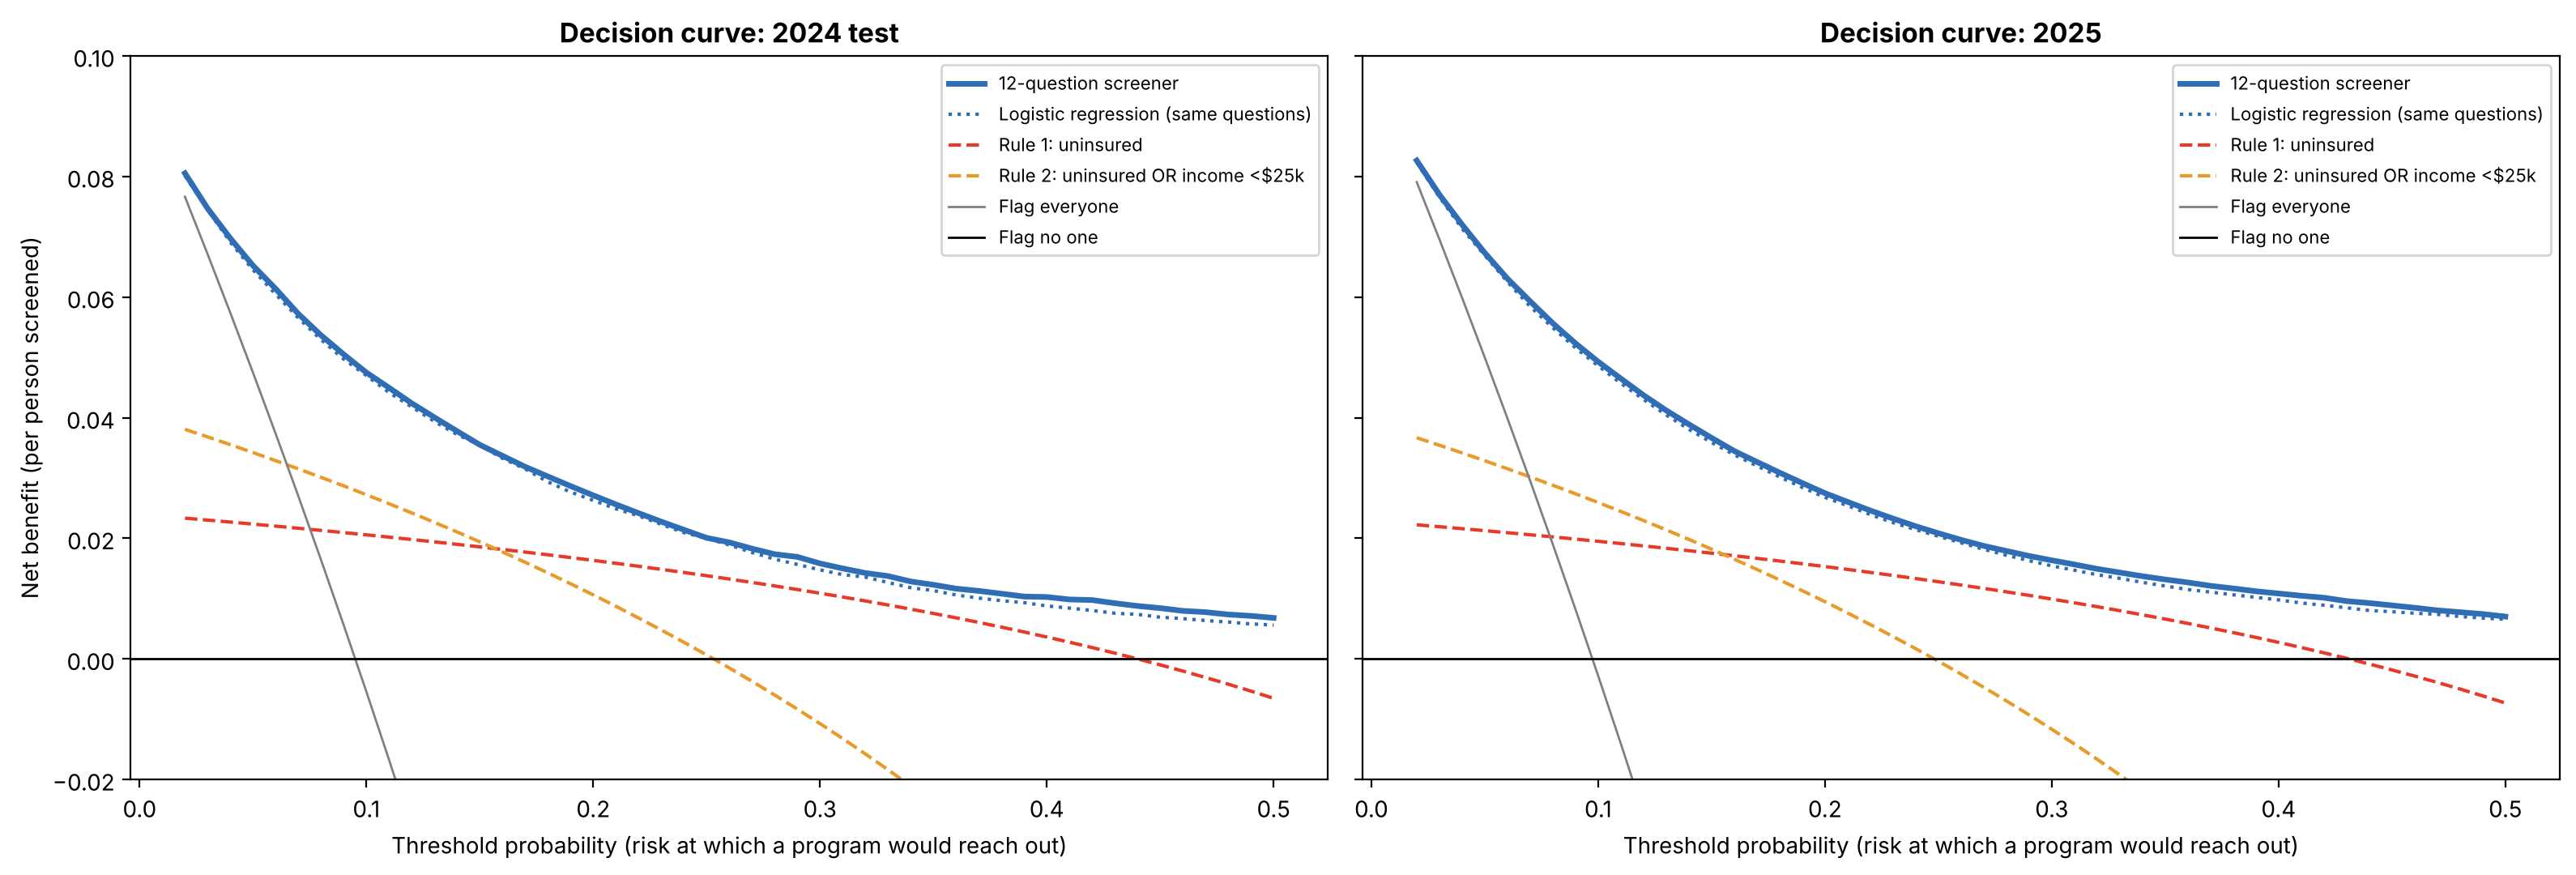

,threshold,12-question screener,Logistic regression (same questions),Rule 1: uninsured,Rule 2: uninsured OR income <$25k,Flag everyone
3,0.05,0.0652,0.0645,0.0224,0.0342,0.0475
8,0.10,0.0475,0.0470,0.0206,0.0272,-0.0054
13,0.15,0.0355,0.0355,0.0186,0.0194,-0.0646
18,0.20,0.0271,0.0263,0.0163,0.0106,-0.1311
28,0.30,0.0158,0.0148,0.0109,-0.0107,-0.2927
38,0.40,0.0103,0.0088,0.0036,-0.0392,-0.5082


In [7]:
ts = np.round(np.arange(0.02, 0.51, 0.01), 2)
def nb_model(y, p, t): n = len(y); f = p >= t; tp = (f & (y == 1)).sum(); fp = (f & (y == 0)).sum(); return (tp - fp * t / (1 - t)) / n
def nb_flag(y, f, t):  n = len(y); tp = (f & (y == 1)).sum(); fp = (f & (y == 0)).sum(); return (tp - fp * t / (1 - t)) / n
dca = {}
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for a, (data, d, y, ps, pl) in zip(ax, [('2024 test', test, yte, p_te_short, p_te_lr), ('2025', d25, y25, p25_short, p25_lr)]):
    cur = pd.DataFrame({'threshold': ts,
        SCREENER: [nb_model(y, ps, t) for t in ts],
        'Logistic regression (same questions)': [nb_model(y, pl, t) for t in ts],
        'Rule 1: uninsured': [nb_flag(y, rules['Rule 1: uninsured'](d), t) for t in ts],
        'Rule 2: uninsured OR income <$25k': [nb_flag(y, rules['Rule 2: uninsured OR income <$25k'](d), t) for t in ts],
        'Flag everyone': [nb_flag(y, np.ones(len(y), bool), t) for t in ts]})
    dca[data] = cur
    for col, sty in [(SCREENER, dict(c='#2f6db5', lw=2.5)), ('Logistic regression (same questions)', dict(c='#2f6db5', ls=':', lw=1.5)),
                     ('Rule 1: uninsured', dict(c='#e63a2a', ls='--')), ('Rule 2: uninsured OR income <$25k', dict(c='#e89a2a', ls='--')),
                     ('Flag everyone', dict(c='grey', lw=1))]:
        a.plot(cur.threshold, cur[col], label=col, **sty)
    a.axhline(0, c='k', lw=1, label='Flag no one'); a.set_ylim(-0.02, max(0.1, cur[SCREENER].max() * 1.15))
    a.set_title(f'Decision curve: {data}', weight='bold'); a.set_xlabel('Threshold probability (risk at which a program would reach out)'); a.legend(fontsize=8)
ax[0].set_ylabel('Net benefit (per person screened)')
plt.tight_layout(); plt.show()
dca['2024 test'].iloc[[3, 8, 13, 18, 28, 38]].round(4)

# STEP 7 · Sensitivity analyses
> **What:** (a) **Complete cases**: test people with no "Unknown" answer among the screener's inputs. (b) **Access variables added**: retrain the screener with `has_personal_doctor` and `last_checkup` added, to measure how much those excluded (leakage-risk) variables would inflate performance.  
> **Why here:** Shows the main result does not depend on how missing answers were handled, and justifies excluding the access variables.  
> **Result of this step:** two robustness checks

In [8]:
cc = (test[[c for c in short['features'] if c not in NUMS]] != 'Unknown').all(axis=1).values
print(f"(a) Complete cases: {cc.sum():,} of {len(cc):,} test people ({100*cc.mean():.1f}%)")
print(f"    screener AUC complete cases {roc_auc_score(yte[cc], p_te_short[cc]):.4f} | with any Unknown {roc_auc_score(yte[~cc], p_te_short[~cc]):.4f} | all {roc_auc_score(yte, p_te_short):.4f}")

aug = short['features'] + ['has_personal_doctor', 'last_checkup']
cats_aug = [c for c in aug if c not in NUMS]
xgb_params = short['model'].named_steps['model'].get_params()
steps_aug = [('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats_aug)] + ([('pt', PowerTransformer(), NUMS)] if NUMS else [])
aug_model = Pipeline([('pre', ColumnTransformer(steps_aug)),
                      ('model', XGBClassifier(**xgb_params))]).fit(train[aug], ytr)
p_aug = aug_model.predict_proba(test[aug])[:, 1]
print(f"(b) Screener + has_personal_doctor + last_checkup: AUC {roc_auc_score(yte, p_aug):.4f} vs screener {roc_auc_score(yte, p_te_short):.4f}"
      f" (gain {roc_auc_score(yte, p_aug) - roc_auc_score(yte, p_te_short):+.4f})")

(a) Complete cases: 65,541 of 91,200 test people (71.9%)
    screener AUC complete cases 0.8445 | with any Unknown 0.8265 | all 0.8394


(b) Screener + has_personal_doctor + last_checkup: AUC 0.8442 vs screener 0.8394 (gain +0.0048)


# STEP 8 · The hidden burden: cost barriers despite insurance or income
> **What:** Among adults who **did** report a cost barrier, what share were insured, or had a middle or high income? And how many of them does the screener catch?  
> **Why here:** The fairness results showed low recall in these groups; this measures how large that hidden population is.  
> **Result of this step:** shares and recall

In [9]:
yes = y_all == 1; w = d24.survey_weight.values
ins = (d24.insurance_type != 'No coverage') & (d24.insurance_type != 'Unknown')
mid = d24.income.isin(['$50k-<100k', '$100k-<200k', '$200k+'])
share = lambda m: 100 * w[yes & m.values].sum() / w[yes].sum()
hidden = {'% of cost-barrier adults who were insured': share(ins),
          '% of cost-barrier adults with income $50k+': share(mid),
          '% of cost-barrier adults insured AND income $50k+': share(ins & mid)}
yp_s = p_te_short >= short['threshold']; ins_t = ((test.insurance_type != 'No coverage') & (test.insurance_type != 'Unknown')).values
mid_t = test.income.isin(['$50k-<100k', '$100k-<200k', '$200k+']).values
for name, m in [('insured', ins_t), ('income $50k+', mid_t), ('insured AND income $50k+', ins_t & mid_t), ('uninsured', (test.insurance_type == 'No coverage').values)]:
    hidden[f'screener recall among {name} (2024 test, weighted)'] = 100 * recall_score(yte[m], yp_s[m], sample_weight=wte[m])
pd.Series(hidden).round(1).to_frame('value (%)')

,value (%)
% of cost-barrier adults who were insured,65.6
% of cost-barrier adults with income $50k+,29.4
% of cost-barrier adults insured AND income $50k+,22.9
"screener recall among insured (2024 test, weighted)",36.2
"screener recall among income $50k+ (2024 test, weighted)",36.2
"screener recall among insured AND income $50k+ (2024 test, weighted)",21.3
"screener recall among uninsured (2024 test, weighted)",94.9


# STEP 9 · Save all numbers for the paper
> **What:** Write every result of this notebook to one JSON file.  
> **Why here:** So each number in the paper can be traced to a file.  
> **Result of this step:** `artifacts/paper_results.json`

In [ ]:
res = {'table1': table1.round(2).to_dict(orient='records'), 'ci': cis, 'calibration': calib_tab.round(4).to_dict(orient='index'),
       'auc_compare': auc_cmp.round(4).to_dict(), 'baselines': baselines.round(4).to_dict(orient='records'),
       'dca': {k: v.round(5).to_dict(orient='list') for k, v in dca.items()}, 'hidden': {k: round(v, 2) for k, v in hidden.items()}}
json.dump(res, open('../models/paper_results.json', 'w'), indent=1, default=float)
print('saved artifacts/paper_results.json')

saved artifacts/paper_results.json
